## 1. Khởi tạo Spark

In [1]:
import os, sys, time

os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
# Spark trên Windows cần hadoop.dll trong PATH để ghi file
os.environ["PATH"] = os.path.join(os.environ.get("HADOOP_HOME", r"C:\hadoop"), "bin") + os.pathsep + os.environ["PATH"]

import pandas as pd
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor

spark = (SparkSession.builder
         .master("local[*]")
         .appName("RussiaRealEstateModeling")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())
spark.version

'3.5.3'

## 2. Đọc dữ liệu

Tập train là toàn bộ `train_model.parquet`; tập đánh giá là 2 tháng đầu của tập test (`months_since_start` 39–40, tức 02/05–30/06/2021).

In [2]:
train = spark.read.parquet("../data/train_model.parquet")
test = spark.read.parquet("../data/test_model.parquet").filter(F.col("months_since_start") <= 40)
print(f"Train: {train.count():,} bản ghi | Test (2 tháng đầu): {test.count():,} bản ghi")

Train: 5,459,594 bản ghi | Test (2 tháng đầu): 1,677,481 bản ghi


## 3. Chuẩn bị đặc trưng

Gộp các đặc trưng thành một vector; mô hình học trên log(`price`) vì giá lệch phải mạnh và tăng theo tỷ lệ, dự đoán được đổi ngược về rúp khi tính metric (đặt `TARGET_LOG = False` để học trực tiếp trên giá).

In [3]:
TARGET_LOG = True
FEATURES = [c for c in train.columns if c != "price"]
assembler = VectorAssembler(inputCols=FEATURES, outputCol="features")
label = F.log("price") if TARGET_LOG else F.col("price").cast("double")

train_vec = assembler.transform(train).withColumn("label", label).select("features", "label").cache()
test_vec = assembler.transform(test).withColumn("label", label).select("price", "features", "label").cache()
print(f"{len(FEATURES)} đặc trưng:", FEATURES)
print(f"Đã cache: train {train_vec.count():,} | test {test_vec.count():,}")

16 đặc trưng: ['geo_lat', 'geo_lon', 'distance_to_capital', 'area', 'rooms', 'is_studio', 'level', 'level_ratio', 'pre_owned_house', 'months_since_start', 'is_moscow_or_spb', 'bt_block', 'bt_brick', 'bt_monolithic', 'bt_others', 'bt_wooden']
Đã cache: train 5,459,594 | test 1,677,481


## 4. Huấn luyện và đánh giá

Hàm tính R², MAE, RMSE, MAPE trên giá gốc (rúp) bằng phép tổng hợp của Spark.

In [4]:
def evaluate(pred):
    p = pred.withColumn("pred_price", F.exp("prediction") if TARGET_LOG else F.col("prediction"))
    err = F.col("price") - F.col("pred_price")
    r = p.agg(F.avg(F.abs(err)).alias("MAE"),
              F.sqrt(F.avg(err ** 2)).alias("RMSE"),
              (100 * F.avg(F.abs(err) / F.col("price"))).alias("MAPE"),
              F.sum(err ** 2).alias("ss_res"),
              F.avg("price").alias("mean_price")).first()
    ss_tot = p.agg(F.sum((F.col("price") - F.lit(r["mean_price"])) ** 2)).first()[0]
    return {"R2": 1 - r["ss_res"] / ss_tot, "MAE": r["MAE"], "RMSE": r["RMSE"], "MAPE (%)": r["MAPE"]}

Huấn luyện Linear Regression, Random Forest và GBT trên toàn bộ tập train (tham số mặc định hợp lý, chưa tinh chỉnh), rồi đánh giá trên 2 tháng đầu của tập test.

In [5]:
models = {
    "Linear Regression": LinearRegression(featuresCol="features", labelCol="label"),
    "Random Forest": RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=30, maxDepth=10, seed=42),
    "GBT": GBTRegressor(featuresCol="features", labelCol="label", maxIter=30, maxDepth=6, seed=42),
}
results, fitted = {}, {}
for name, estimator in models.items():
    t0 = time.time()
    fitted[name] = estimator.fit(train_vec)
    fit_time = time.time() - t0
    results[name] = {**evaluate(fitted[name].transform(test_vec)), "Thời gian huấn luyện (s)": fit_time}
    print(f"{name}: xong sau {fit_time:.0f}s")

metrics = pd.DataFrame(results).T
metrics.style.format({"R2": "{:.4f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE (%)": "{:.2f}",
                      "Thời gian huấn luyện (s)": "{:.0f}"})

Linear Regression: xong sau 10s
Random Forest: xong sau 615s
GBT: xong sau 419s


,R2,MAE,RMSE,MAPE (%),Thời gian huấn luyện (s)
Linear Regression,0.3958,"2,225,274","6,693,931",39.60,10
Random Forest,0.6520,"1,637,606","5,079,920",26.84,615
GBT,0.7383,"1,406,028","4,405,713",24.21,419


## 5. Độ quan trọng đặc trưng

Độ quan trọng (`featureImportances`) của Random Forest và GBT đã huấn luyện ở trên, xếp theo GBT.

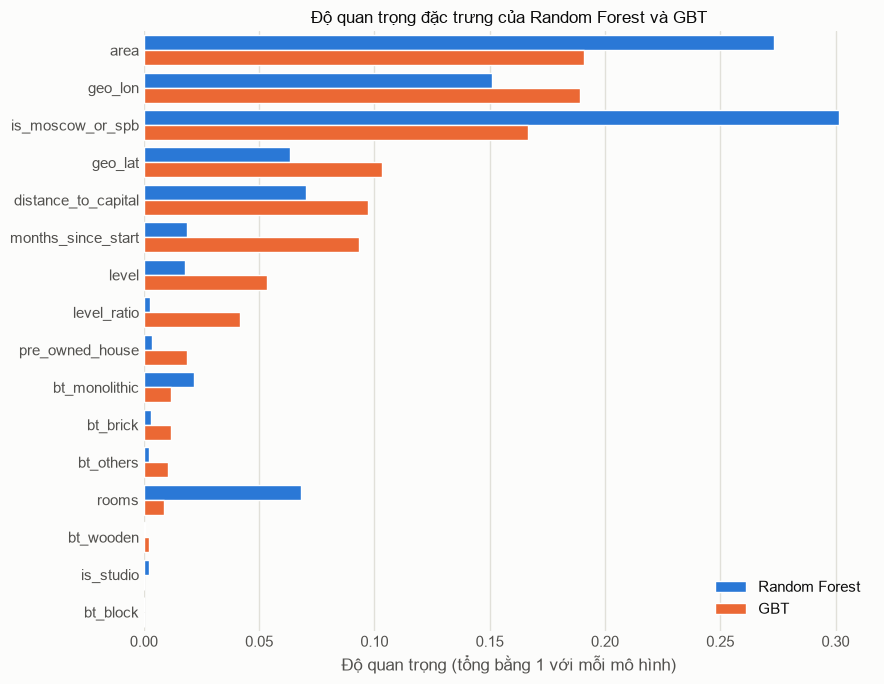

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white", rc={
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
importance = (pd.DataFrame({name: fitted[name].featureImportances.toArray() for name in ["Random Forest", "GBT"]},
                           index=FEATURES)
                .sort_values("GBT", ascending=False))
imp_long = importance.rename_axis("feature").reset_index().melt(id_vars="feature", var_name="model", value_name="importance")

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=imp_long, x="importance", y="feature", hue="model", hue_order=["Random Forest", "GBT"],
            palette={"Random Forest": "#2a78d6", "GBT": "#eb6834"}, saturation=1, ax=ax)
ax.set(xlabel="Độ quan trọng (tổng bằng 1 với mỗi mô hình)", ylabel=None, title="Độ quan trọng đặc trưng của Random Forest và GBT")
ax.legend(title=None, frameon=False, loc="lower right")
ax.grid(axis="x", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## 6. GBT với `province` và tách xu hướng

Chỉ dùng GBT; thêm `province`, bỏ `is_studio`, `is_moscow_or_spb`, `building_type` và `rooms`. `train_model`/`test_model` không có `province` nên mục này đọc `train.parquet` và `test.parquet` (cả năm 2021), chạy độc lập với các mục 2–5 (chỉ cần cell khởi tạo Spark).

In [7]:
import numpy as np
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder

spark.catalog.clearCache()  # giải phóng dữ liệu đã cache ở các mục trên (nếu có)
FEATS = ["geo_lat", "geo_lon", "distance_to_capital", "area", "level", "level_ratio", "pre_owned_house"]

def load(path):
    return (spark.read.parquet(path).select("price", *FEATS, "months_since_start", "province")
                 .withColumn("price", F.col("price").cast("double")).withColumn("label", F.log("price")))

train_gbt = load("../data/train.parquet").cache()
test_gbt = load("../data/test.parquet").cache()
LAST_MONTH = train_gbt.agg(F.max("months_since_start")).first()[0]
print(f"Train: {train_gbt.count():,} bản ghi | Test (05–12/2021): {test_gbt.count():,} bản ghi | tháng cuối của train: {LAST_MONTH}")

Train: 5,459,594 bản ghi | Test (05–12/2021): 7,469,831 bản ghi | tháng cuối của train: 39


Bước 1, phần xu hướng: LR hedonic học log(`price`) theo các đặc trưng, one-hot `province` và một biến giả cho mỗi tháng; hệ số của từng tháng là chỉ số giá của tháng đó sau khi đã loại ảnh hưởng của thành phần căn hộ.

In [8]:
# Tỉnh mốc là tỉnh nhiều bản ghi nhất (frequencyAsc xếp tỉnh này cuối cùng để OneHotEncoder bỏ đi);
# biến giả tháng giữ đủ và thay cho hệ số chặn để tránh đa cộng tuyến
hedonic = Pipeline(stages=[
    StringIndexer(inputCol="province", outputCol="province_idx", stringOrderType="frequencyAsc"),
    OneHotEncoder(inputCols=["province_idx"], outputCols=["province_ohe"]),
    OneHotEncoder(inputCols=["months_since_start"], outputCols=["month_ohe"], dropLast=False),
    VectorAssembler(inputCols=FEATS + ["province_ohe", "month_ohe"], outputCol="features"),
    LinearRegression(featuresCol="features", labelCol="label", fitIntercept=False),
]).fit(train_gbt)
n_months = hedonic.stages[2].categorySizes[0]
month_index = hedonic.stages[-1].coefficients.toArray()[-n_months:]
print(f"Chỉ số giá cho {n_months} tháng, từ 02/2018 đến {(pd.Period('2018-02', 'M') + n_months - 1).strftime('%m/%Y')}")

Chỉ số giá cho 40 tháng, từ 02/2018 đến 05/2021


Ngoại suy chỉ số cho các tháng sau giai đoạn train bằng đường thẳng khớp trên 12 tháng đầy đủ cuối của train (05/2020–04/2021; tháng 05/2021 của train chỉ có ngày 01/05 nên không dùng).

In [9]:
TREND_MONTHS = 12
fit_months = np.arange(LAST_MONTH - TREND_MONTHS, LAST_MONTH)
slope, intercept = np.polyfit(fit_months, month_index[fit_months], 1)
print(f"Xu hướng: {100 * (np.exp(slope) - 1):+.2f}% mỗi tháng")

Xu hướng: +2.42% mỗi tháng


Vẽ chỉ số giá theo tháng (so với 04/2021) cùng đường xu hướng khớp trên 12 tháng và phần ngoại suy cho các tháng của tập test; chỉ vẽ các tháng có trên 500 bản ghi (02–08/2018 chỉ có vài chục bản ghi mỗi tháng nên chỉ số rất nhiễu).

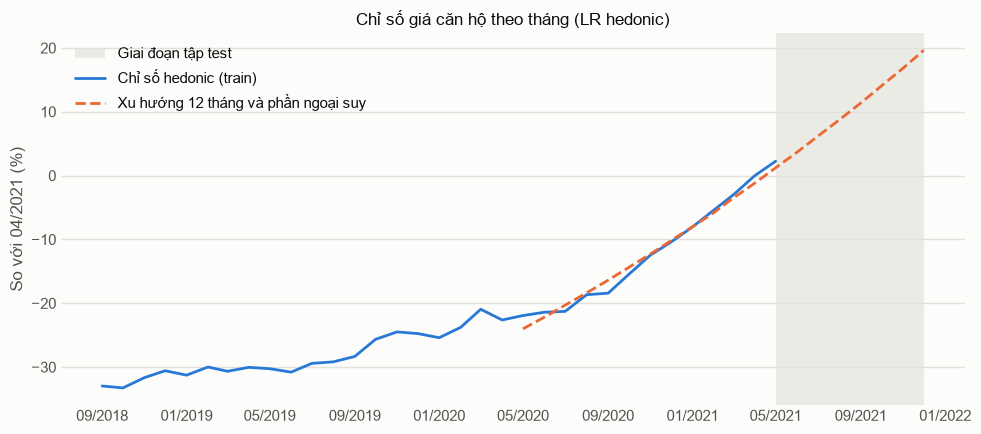

In [10]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

to_date = lambda m: (pd.Period("2018-02", "M") + int(m)).to_timestamp()
test_months = np.arange(LAST_MONTH, test_gbt.agg(F.max("months_since_start")).first()[0] + 1)
ref = month_index[LAST_MONTH - 1]  # 04/2021
trend_range = np.arange(fit_months[0], test_months[-1] + 1)
month_counts = train_gbt.groupBy("months_since_start").count().toPandas().set_index("months_since_start")["count"]
shown = [m for m in range(n_months) if month_counts.get(m, 0) > 500]
index_df = pd.DataFrame({"Tháng": [to_date(m) for m in shown], "Chỉ số (%)": 100 * (np.exp(month_index[shown] - ref) - 1)})
trend_df = pd.DataFrame({"Tháng": [to_date(m) for m in trend_range],
                         "Chỉ số (%)": 100 * (np.exp(intercept + slope * trend_range - ref) - 1)})

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axvspan(to_date(test_months[0]), to_date(test_months[-1]), color="#e1e0d9", alpha=0.6, linewidth=0, label="Giai đoạn tập test")
sns.lineplot(data=index_df, x="Tháng", y="Chỉ số (%)", color="#2a78d6", linewidth=2, label="Chỉ số hedonic (train)", ax=ax)
sns.lineplot(data=trend_df, x="Tháng", y="Chỉ số (%)", color="#eb6834", linewidth=2, linestyle="--",
             label=f"Xu hướng {TREND_MONTHS} tháng và phần ngoại suy", ax=ax)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set(xlabel=None, ylabel="So với 04/2021 (%)", title="Chỉ số giá căn hộ theo tháng (LR hedonic)")
ax.legend(title=None, frameon=False, loc="upper left")
ax.grid(axis="y", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

Bước 2: GBT học phần còn lại log(`price`) − chỉ số tháng và không dùng `months_since_start`; GBT gốc học thẳng log(`price`) có `months_since_start` để đối chiếu, cùng tham số (`maxBins=128` vì `province` có 84 nhóm).

In [11]:
idx_df = spark.createDataFrame([(m, float(v)) for m, v in enumerate(month_index)], ["months_since_start", "month_idx"])
train_resid = (train_gbt.join(F.broadcast(idx_df), "months_since_start")
                        .withColumn("resid", F.col("label") - F.col("month_idx")))

def gbt_pipeline(features, label):
    return Pipeline(stages=[
        StringIndexer(inputCol="province", outputCol="province_idx", handleInvalid="keep"),
        VectorAssembler(inputCols=features + ["province_idx"], outputCol="features"),
        GBTRegressor(featuresCol="features", labelCol=label, maxIter=30, maxDepth=6, maxBins=128, seed=42)])

gbt_models = {}
for name, features, label, data in [("GBT gốc", FEATS + ["months_since_start"], "label", train_gbt),
                                    ("GBT tách xu hướng", FEATS, "resid", train_resid)]:
    t0 = time.time()
    gbt_models[name] = gbt_pipeline(features, label).fit(data)
    print(f"{name}: xong sau {time.time() - t0:.0f}s")

GBT gốc: xong sau 409s
GBT tách xu hướng: xong sau 527s


Dự đoán trên tập test rồi đổi về rúp; với bản tách xu hướng, giá dự đoán là exp(GBT + chỉ số ngoại suy của tháng).

In [12]:
trend = F.lit(float(intercept)) + F.lit(float(slope)) * F.col("months_since_start")
pred_log = {"GBT gốc": F.col("prediction"), "GBT tách xu hướng": F.col("prediction") + trend}
predictions = {name: gbt_models[name].transform(test_gbt)
                         .select("months_since_start", "price", F.exp(pred_log[name]).alias("pred_price")).cache()
               for name in gbt_models}

Tính R², MAE, RMSE, MAPE, thêm MdAPE (sai số phần trăm trung vị) và độ lệch trung vị (dự đoán/thực − 1), trên 2 tháng đầu (kết quả chính) và cả năm 2021.

In [13]:
def evaluate_with_median(pred):
    err = F.col("price") - F.col("pred_price")
    mean_price = pred.agg(F.avg("price")).first()[0]
    return pred.agg((1 - F.sum(err ** 2) / F.sum((F.col("price") - F.lit(mean_price)) ** 2)).alias("R2"),
                    F.avg(F.abs(err)).alias("MAE"),
                    F.sqrt(F.avg(err ** 2)).alias("RMSE"),
                    (100 * F.avg(F.abs(err) / F.col("price"))).alias("MAPE (%)"),
                    (100 * F.percentile_approx(F.abs(err) / F.col("price"), 0.5, 10000)).alias("MdAPE (%)"),
                    (100 * (F.percentile_approx(F.col("pred_price") / F.col("price"), 0.5, 10000) - 1)).alias("Lệch trung vị (%)"),
                    ).first().asDict()

scopes = {"2 tháng đầu (05–06/2021)": F.col("months_since_start") <= 40, "Cả năm (05–12/2021)": F.lit(True)}
gbt_metrics = (pd.DataFrame([{"Phạm vi": scope, "Mô hình": name, **evaluate_with_median(pred.filter(cond))}
                             for scope, cond in scopes.items() for name, pred in predictions.items()])
                 .set_index(["Phạm vi", "Mô hình"]))
gbt_metrics.style.format({"R2": "{:.4f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE (%)": "{:.2f}",
                          "MdAPE (%)": "{:.2f}", "Lệch trung vị (%)": "{:+.2f}"})

Độ lệch trung vị theo từng tháng của tập test, để xem mô hình có đoán thấp dần khi giá tiếp tục tăng sau giai đoạn train hay không.

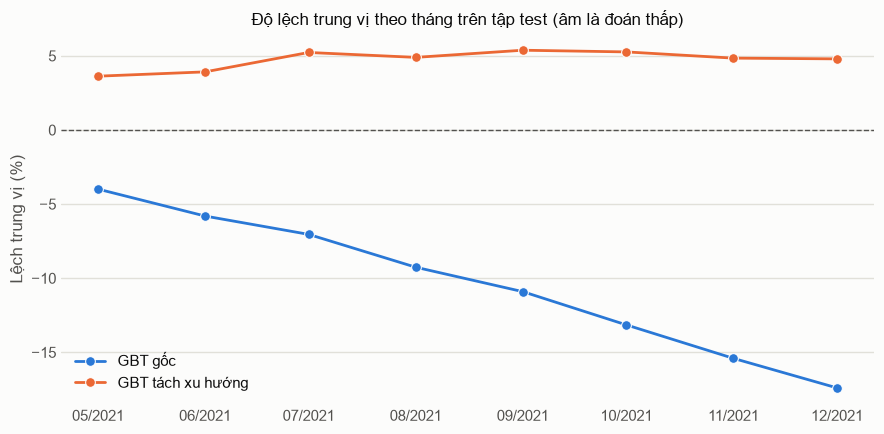

In [14]:
monthly_bias = pd.concat([
    pred.groupBy("months_since_start")
        .agg((100 * (F.percentile_approx(F.col("pred_price") / F.col("price"), 0.5, 10000) - 1)).alias("Lệch trung vị (%)"))
        .toPandas().assign(**{"Mô hình": name})
    for name, pred in predictions.items()]).sort_values("months_since_start")
monthly_bias["Tháng"] = monthly_bias["months_since_start"].map(to_date)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=monthly_bias, x="Tháng", y="Lệch trung vị (%)", hue="Mô hình", hue_order=list(predictions),
             palette={"GBT gốc": "#2a78d6", "GBT tách xu hướng": "#eb6834"}, linewidth=2, marker="o", markersize=7, ax=ax)
ax.axhline(0, color="#52514e", linewidth=1, linestyle="--")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set(xlabel=None, title="Độ lệch trung vị theo tháng trên tập test (âm là đoán thấp)")
ax.legend(title=None, frameon=False, loc="lower left")
ax.grid(axis="y", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## 7. Hybrid 3 nhóm và hiệu chỉnh độ lệch

Chia dữ liệu thành 3 nhóm Moscow / Saint Petersburg / các vùng còn lại; mỗi nhóm có LR hedonic, đường xu hướng và GBT riêng như mục 6, thêm bước hiệu chỉnh độ lệch của chỉ số tháng. Mục này dùng lại dữ liệu, đặc trưng và hàm đánh giá của mục 6.

Gán nhóm cho từng bản ghi; Moscow và Saint Petersburg mỗi nhóm chỉ có một tỉnh nên hai nhóm này không dùng `province`.

In [ ]:
from functools import reduce
from pyspark.sql import DataFrame

GROUPS = ["Moscow", "Saint Petersburg", "Còn lại"]
group_col = (F.when(F.col("province") == "Moscow", "Moscow")
              .when(F.col("province") == "Saint Petersburg", "Saint Petersburg").otherwise("Còn lại"))
train_grp, test_grp = train_gbt.withColumn("group", group_col), test_gbt.withColumn("group", group_col)
train_grp.groupBy("group").count().toPandas().set_index("group").loc[GROUPS]

Hàm huấn luyện cho một nhóm: chỉ số tháng từ LR hedonic, GBT học phần còn lại, rồi hiệu chỉnh: trên train, lấy mức GBT còn đoán lệch trong từng tháng (trung vị), cộng vào chỉ số của tháng đó và khớp lại đường xu hướng 12 tháng.

In [ ]:
def fit_group(tr, use_province):
    prov_stages = [StringIndexer(inputCol="province", outputCol="province_idx", stringOrderType="frequencyAsc"),
                   OneHotEncoder(inputCols=["province_idx"], outputCols=["province_ohe"])] if use_province else []
    hedonic = Pipeline(stages=prov_stages + [
        OneHotEncoder(inputCols=["months_since_start"], outputCols=["month_ohe"], dropLast=False),
        VectorAssembler(inputCols=FEATS + (["province_ohe"] if use_province else []) + ["month_ohe"], outputCol="features"),
        LinearRegression(featuresCol="features", labelCol="label", fitIntercept=False),
    ]).fit(tr)
    n = hedonic.stages[-3].categorySizes[0]
    index = hedonic.stages[-1].coefficients.toArray()[-n:]

    idx_df = spark.createDataFrame([(m, float(v)) for m, v in enumerate(index)], ["months_since_start", "month_idx"])
    tr_resid = tr.join(F.broadcast(idx_df), "months_since_start").withColumn("resid", F.col("label") - F.col("month_idx"))
    gbt = Pipeline(stages=([StringIndexer(inputCol="province", outputCol="province_idx", handleInvalid="keep")] if use_province else []) + [
        VectorAssembler(inputCols=FEATS + (["province_idx"] if use_province else []), outputCol="features"),
        GBTRegressor(featuresCol="features", labelCol="resid", maxIter=30, maxDepth=6, maxBins=128, seed=42),
    ]).fit(tr_resid)

    # Mức đoán lệch trung vị (theo log) của GBT trong từng tháng trên train
    bias = (gbt.transform(tr_resid).groupBy("months_since_start")
               .agg(F.percentile_approx(F.col("resid") - F.col("prediction"), 0.5, 10000).alias("bias"))
               .toPandas().set_index("months_since_start")["bias"].reindex(range(n), fill_value=0).to_numpy())
    slope_raw = np.polyfit(fit_months, index[fit_months], 1)[0]
    slope_adj, intercept_adj = np.polyfit(fit_months, (index + bias)[fit_months], 1)
    return {"gbt": gbt, "slope_raw": slope_raw, "slope": slope_adj, "intercept": intercept_adj}

Huấn luyện 3 nhóm và so tốc độ tăng giá của đường xu hướng trước và sau hiệu chỉnh.

In [ ]:
hybrid = {}
for g in GROUPS:
    t0 = time.time()
    hybrid[g] = fit_group(train_grp.filter(F.col("group") == g), use_province=(g == "Còn lại"))
    print(f"{g}: xong sau {time.time() - t0:.0f}s | xu hướng {100 * (np.exp(hybrid[g]['slope_raw']) - 1):+.2f}%/tháng, "
          f"sau hiệu chỉnh {100 * (np.exp(hybrid[g]['slope']) - 1):+.2f}%/tháng")

Dự đoán trên tập test: mỗi nhóm dùng mô hình của nhóm mình, giá dự đoán là exp(GBT + chỉ số ngoại suy sau hiệu chỉnh); dự đoán của hai mô hình ở mục 6 được tính lại kèm cột nhóm để so theo nhóm.

In [ ]:
HYBRID = "Hybrid 3 nhóm + hiệu chỉnh"

def to_rubles(df, log_pred):
    return df.select("months_since_start", "price", "group", F.exp(log_pred).alias("pred_price"))

predictions_grp = {name: to_rubles(gbt_models[name].transform(test_grp), pred_log[name]).cache() for name in gbt_models}
predictions_grp[HYBRID] = reduce(DataFrame.unionByName, [
    to_rubles(hybrid[g]["gbt"].transform(test_grp.filter(F.col("group") == g)),
              F.col("prediction") + F.lit(float(hybrid[g]["intercept"])) + F.lit(float(hybrid[g]["slope"])) * F.col("months_since_start"))
    for g in GROUPS]).cache()

Tính các metric như mục 6 cho bản hybrid và đặt cạnh hai mô hình của mục 6.

In [ ]:
hybrid_metrics = pd.DataFrame([{"Phạm vi": scope, "Mô hình": HYBRID, **evaluate_with_median(predictions_grp[HYBRID].filter(cond))}
                               for scope, cond in scopes.items()]).set_index(["Phạm vi", "Mô hình"])
all_metrics = pd.concat([gbt_metrics, hybrid_metrics]).loc[[(s, m) for s in scopes for m in predictions_grp]]
all_metrics.style.format({"R2": "{:.4f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE (%)": "{:.2f}",
                          "MdAPE (%)": "{:.2f}", "Lệch trung vị (%)": "{:+.2f}"})

MdAPE và độ lệch trung vị theo từng nhóm, để xem hybrid cải thiện ở nhóm nào.

In [ ]:
def median_errors_by_group(pred):
    rel = F.col("pred_price") / F.col("price")
    return (pred.groupBy("group")
                .agg((100 * F.percentile_approx(F.abs(rel - 1), 0.5, 10000)).alias("MdAPE (%)"),
                     (100 * (F.percentile_approx(rel, 0.5, 10000) - 1)).alias("Lệch trung vị (%)"))
                .toPandas())

group_metrics = (pd.concat([median_errors_by_group(pred.filter(cond)).assign(**{"Phạm vi": scope, "Mô hình": name})
                            for scope, cond in scopes.items() for name, pred in predictions_grp.items()])
                   .pivot_table(index=["Phạm vi", "Mô hình"], columns="group", values=["MdAPE (%)", "Lệch trung vị (%)"], sort=False)
                   .reindex(columns=GROUPS, level=1))
group_metrics.style.format("{:.2f}").format("{:+.2f}", subset=["Lệch trung vị (%)"])

Độ lệch trung vị theo tháng của bản hybrid, vẽ cùng hai mô hình của mục 6.

In [ ]:
hybrid_bias = (predictions_grp[HYBRID].groupBy("months_since_start")
                   .agg((100 * (F.percentile_approx(F.col("pred_price") / F.col("price"), 0.5, 10000) - 1)).alias("Lệch trung vị (%)"))
                   .toPandas().assign(**{"Mô hình": HYBRID}))
hybrid_bias["Tháng"] = hybrid_bias["months_since_start"].map(to_date)
bias_all = pd.concat([monthly_bias, hybrid_bias]).sort_values("months_since_start")

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.lineplot(data=bias_all, x="Tháng", y="Lệch trung vị (%)", hue="Mô hình", hue_order=list(predictions_grp),
             palette={"GBT gốc": "#2a78d6", "GBT tách xu hướng": "#eb6834", HYBRID: "#1baf7a"},
             linewidth=2, marker="o", markersize=7, ax=ax)
ax.axhline(0, color="#52514e", linewidth=1, linestyle="--")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set(xlabel=None, title="Độ lệch trung vị theo tháng trên tập test (âm là đoán thấp)")
ax.legend(title=None, frameon=False, loc="lower left")
ax.grid(axis="y", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()